# Homework 1 - Problem 4: Are the residuals normal?

Squared-error loss is often justified by assuming the residuals are (approximately) normal.
Here we fit several regression models on the Average Localization Error (ALE) dataset,
predict `ale` from the first 4 variables (ignoring `sd_ale`), and test the residuals for normality
with a QQ plot and `scipy.stats.normaltest`.

## Step 1: Imports and settings

In [3]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

SEED = 0
np.random.seed(SEED)
plt.rcParams["figure.dpi"] = 100

## Step 2: Load the ALE dataset

The dataset is "Average Localization Error (ALE) in sensor node localization process in WSNs" (UCI).
We first look for a local CSV, then download the UCI zip file (dataset id 844), with `ucimlrepo` as a fallback.

In [4]:
def load_ale():
    for name in ["ale.csv", "ALE.csv", "ale_dataset.csv"]:
        if os.path.exists(name):
            return pd.read_csv(name)
    import io, zipfile, urllib.request
    url = "https://archive.ics.uci.edu/static/public/844/average+localization+error+(ale)+in+sensor+node+localization+process+in+wsns.zip"
    try:
        raw = urllib.request.urlopen(url).read()
        z = zipfile.ZipFile(io.BytesIO(raw))
        csv_name = [n for n in z.namelist() if n.lower().endswith(".csv")][0]
        return pd.read_csv(z.open(csv_name))
    except Exception as e:
        print("Direct download failed:", e)
    from ucimlrepo import fetch_ucirepo  # pip install ucimlrepo
    ds = fetch_ucirepo(id=844)
    return pd.concat([ds.data.features, ds.data.targets], axis=1)

df = load_ale()
df.to_csv("ale.csv", index=False)
print(df.shape)
print(df.columns.tolist())
df.head()

(107, 6)
['anchor_ratio', 'trans_range', 'node_density', 'iterations', 'ale', 'sd_ale']


,anchor_ratio,trans_range,node_density,iterations,ale,sd_ale
0,30,15,200,40,0.773546,0.250555
1,15,15,100,70,0.911941,0.498329
2,30,15,100,50,0.814867,0.255546
3,15,20,100,20,1.435332,0.394603
4,30,15,100,40,1.265909,0.302943


## Step 3: Select features and split the data

Use the first 4 columns as features, `ale` as the target, and drop `sd_ale`. Split 80/20.

In [5]:
df.columns = [c.strip().lower() for c in df.columns]
feature_cols = df.columns[:4].tolist()
print("Features:", feature_cols)

X = df[feature_cols].values
y = df["ale"].values

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
print(X_train.shape, X_test.shape)

Features: ['anchor_ratio', 'trans_range', 'node_density', 'iterations']
(85, 4) (22, 4)


## Step 4: Define the models

Linear regression, RBF-kernel SVR, a decision tree, and a small neural network.
Scaling is applied inside a pipeline for the scale-sensitive models.

In [6]:
models = {
    "Linear Regression": LinearRegression(),
    "SVR (RBF)": make_pipeline(StandardScaler(), SVR(kernel="rbf", C=1.0)),
    "Decision Tree": DecisionTreeRegressor(max_depth=6, random_state=SEED),
    "Neural Network": make_pipeline(
        StandardScaler(),
        MLPRegressor(hidden_layer_sizes=(64, 64), max_iter=2000, random_state=SEED),
    ),
}
list(models)

['Linear Regression', 'SVR (RBF)', 'Decision Tree', 'Neural Network']

## Step 5: Fit the models and compute test residuals

Residual = `y_test - y_pred`.

In [7]:
residuals = {}
rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    residuals[name] = y_test - pred
    rows.append({
        "model": name,
        "test MAE": mean_absolute_error(y_test, pred),
        "test RMSE": np.sqrt(mean_squared_error(y_test, pred)),
    })
pd.DataFrame(rows).set_index("model")

,test MAE,test RMSE
model,,
Linear Regression,0.192072,0.227181
SVR (RBF),0.145965,0.187415
Decision Tree,0.153638,0.221359
Neural Network,0.145837,0.191968


## Step 6: Normality diagnostics helper

For each model we compute skewness, excess kurtosis, the D'Agostino-Pearson `normaltest`
(null hypothesis: residuals are normally distributed), and draw a histogram with a normal fit and a QQ plot.

In [8]:
def normality_report(res):
    stat, p = stats.normaltest(res)
    return {
        "n": len(res),
        "skew": stats.skew(res),
        "excess kurtosis": stats.kurtosis(res),
        "normaltest stat": stat,
        "normaltest p-value": p,
    }

def plot_diagnostics(name, res):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    axes[0].hist(res, bins=40, density=True, alpha=0.7)
    grid = np.linspace(res.min(), res.max(), 300)
    axes[0].plot(grid, stats.norm.pdf(grid, res.mean(), res.std()), "r-", label="fitted normal")
    axes[0].set_title(f"{name}: residual histogram")
    axes[0].set_xlabel("residual")
    axes[0].legend()
    stats.probplot(res, dist="norm", plot=axes[1])
    axes[1].set_title(f"{name}: QQ plot")
    plt.tight_layout()
    plt.show()

## Step 7: Diagnostics for each model

### 7.1 Linear Regression

{'n': 22, 'skew': 0.45537741060778647, 'excess kurtosis': -0.4221198776337811, 'normaltest stat': 1.0764033245963462, 'normaltest p-value': 0.5837971734013365}


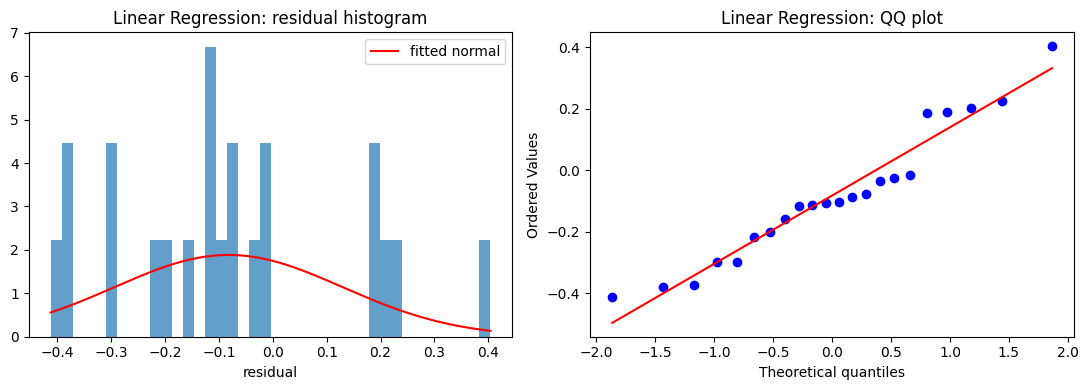

In [9]:
name = "Linear Regression"
print(normality_report(residuals[name]))
plot_diagnostics(name, residuals[name])

### 7.2 SVR (RBF)

{'n': 22, 'skew': 1.4971054738189076, 'excess kurtosis': 2.949011159727652, 'normaltest stat': 15.506299462341211, 'normaltest p-value': 0.0004293879517842845}


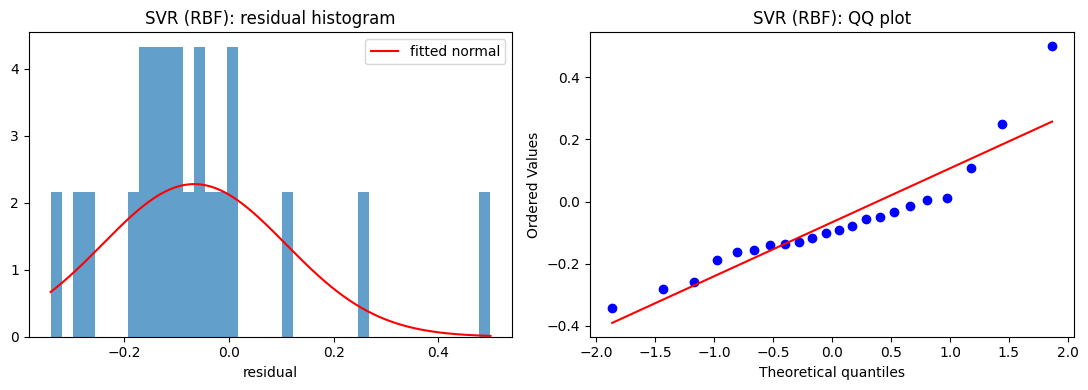

In [10]:
name = "SVR (RBF)"
print(normality_report(residuals[name]))
plot_diagnostics(name, residuals[name])

### 7.3 Decision Tree

{'n': 22, 'skew': 0.9785909691932423, 'excess kurtosis': 2.126368455853176, 'normaltest stat': 9.38974904025356, 'normaltest p-value': 0.009142014434733937}


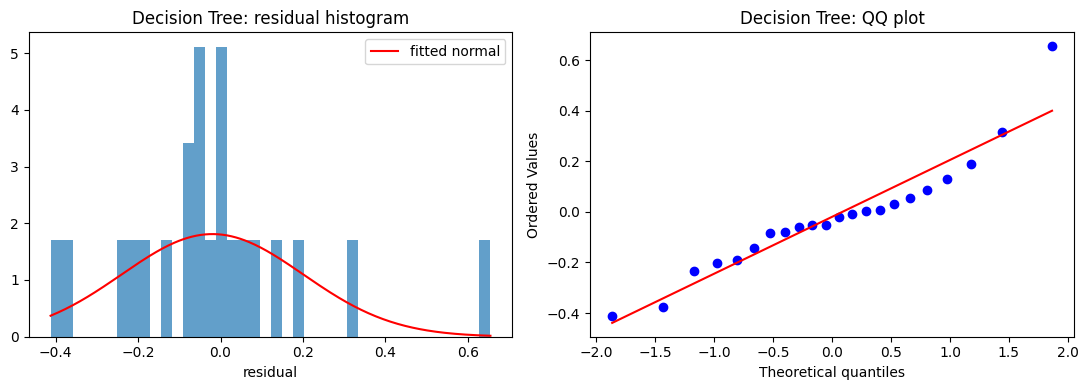

In [11]:
name = "Decision Tree"
print(normality_report(residuals[name]))
plot_diagnostics(name, residuals[name])

### 7.4 Neural Network

{'n': 22, 'skew': 0.7047364115477889, 'excess kurtosis': 1.07769243059807, 'normaltest stat': 5.008450251415175, 'normaltest p-value': 0.08173891083307079}


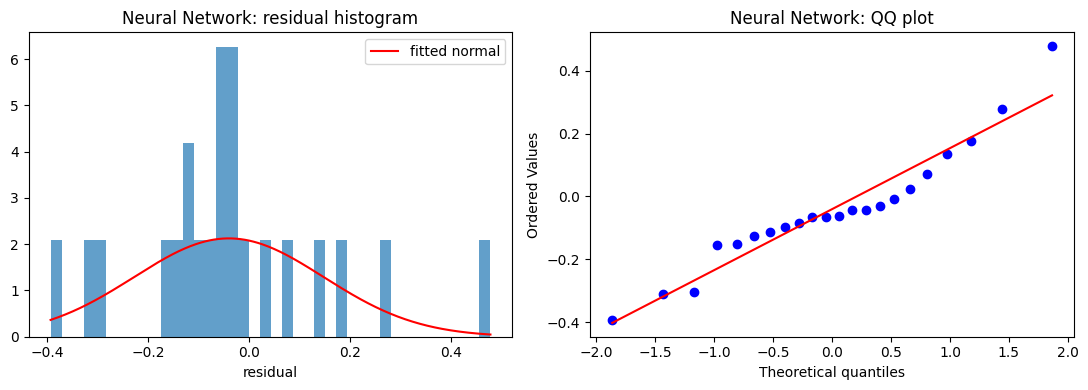

In [12]:
name = "Neural Network"
print(normality_report(residuals[name]))
plot_diagnostics(name, residuals[name])

## Step 8: Summary table

In [13]:
summary = pd.DataFrame({name: normality_report(r) for name, r in residuals.items()}).T
summary

,n,skew,excess kurtosis,normaltest stat,normaltest p-value
Linear Regression,22.0,0.455377,-0.422120,1.076403,0.583797
SVR (RBF),22.0,1.497105,2.949011,15.506299,0.000429
Decision Tree,22.0,0.978591,2.126368,9.389749,0.009142
Neural Network,22.0,0.704736,1.077692,5.008450,0.081739


## Step 9: Sanity check on training residuals

The test set has only 22 points, so the normality test has low power. As a check, repeat the diagnostics on the training residuals (85 points). Run this cell after Step 5.

In [14]:
train_res = {name: y_train - m.predict(X_train) for name, m in models.items()}
pd.DataFrame({name: normality_report(r) for name, r in train_res.items()}).T

,n,skew,excess kurtosis,normaltest stat,normaltest p-value
Linear Regression,85.0,1.364568,4.349895,34.785004,2.795970e-08
SVR (RBF),85.0,1.733219,4.565271,42.728613,5.267441e-10
Decision Tree,85.0,-0.085841,3.161745,11.717344,2.855033e-03
Neural Network,85.0,1.046867,4.076232,27.691244,9.703373e-07


## Step 10: Conclusion

**Test-set residuals (n = 22).** The evidence is mixed. Linear regression (p = 0.58) and the neural network (p = 0.08) are not rejected at the 5% level, while SVR (p = 0.0004) and the decision tree (p = 0.009) are rejected. All four models have positively skewed residuals (skew 0.46 to 1.50), and every model except linear regression has positive excess kurtosis (1.08 to 2.95), i.e. heavier tails than a normal distribution. The QQ plots show the same pattern: the upper tail bends away from the reference line.

**Caveat.** With only 22 test points (107 rows in total), the normality test has low power, so a large p-value is not evidence that the residuals are normal. On the training residuals (about 85 points, Step 9) every model is strongly non-normal (normaltest p between 3e-3 and 5e-10, skew up to 1.7, excess kurtosis up to 4.6).

**Answer.** The residuals are right-skewed and heavy-tailed, so the "approximately normal residuals" justification for squared-error loss is not well supported on this dataset. This motivates robust, heavier-tailed losses such as the Student-t negative log-likelihood used in Problem 5.